In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pickle

from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score

# 1. Đọc dữ liệu từ file đã xử lý ở các stage trước


In [2]:
df = pd.read_csv('../data/NguyenTheHoang_final_eda.csv',low_memory=False)
df.head()

,Transaction ID,Transaction Date,Product Name,Quantity,Price,Store Location,Source,Sales Amount,Month,Weekday,Price Range,Source_Cafe Sales,Source_Coffee Shop Sales,Sales Amount (scaled)
0,TXN_1961373,2023-09-08,Coffee,2.0,2.0,Takeaway,Cafe Sales,4.0,9,Friday,Low,True,False,-0.211372
1,TXN_4977031,2023-05-16,Cake,4.0,3.0,In-store,Cafe Sales,12.0,5,Tuesday,Medium,True,False,1.583948
2,TXN_4271903,2023-07-19,Cookie,4.0,1.0,In-store,Cafe Sales,4.0,7,Wednesday,Low,True,False,-0.211372
3,TXN_7034554,2023-04-27,Salad,2.0,5.0,Takeaway,Cafe Sales,10.0,4,Thursday,Medium,True,False,1.135118
4,TXN_3160411,2023-06-11,Coffee,2.0,2.0,In-store,Cafe Sales,4.0,6,Sunday,Low,True,False,-0.211372


# 2. Tạo nhãn Target (Ví dụ: Giao dịch giá trị cao dựa trên phân vị 75% của Sales Amount)
# Hoặc nếu đã có cột 'Price Range', có thể map trực tiếp

In [3]:
threshold = df['Sales Amount'].quantile(0.75)
df['High_Value'] = (df['Sales Amount'] > threshold).astype(int)

# Chọn các biến đặc trưng (Features) và nhãn (Target)
# Loại bỏ các cột không cần thiết hoặc trùng lặp với target

In [4]:
features = ['Store Location', 'Source', 'Month', 'Weekday', 'Product Name']
X = df[features].copy()
y = df['High_Value'].astype(int)
numeric_features = ['Month']
categorical_features = ['Store Location', 'Source', 'Weekday', 'Product Name']
for col in numeric_features:
    X[col] = pd.to_numeric(X[col], errors='coerce')

for col in categorical_features:
    X[col] = X[col].astype(str)

print(y.value_counts(normalize=True).round(3)) 

High_Value
0    0.8
1    0.2
Name: proportion, dtype: float64


# 3. Chia tập train/test (80/20)

In [5]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 4. Xây dựng Pipeline tiền xử lý

In [6]:
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ])

# 5. Khởi tạo 2 mô hình (có dùng class_weight='balanced' để xử lý mất cân bằng lớp nếu có)

In [7]:
models = {
    'Logistic Regression': Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42))
    ]),
    'Decision Tree': Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', DecisionTreeClassifier(class_weight='balanced', max_depth=8, random_state=42))
    ])
}

# 6. Huấn luyện và Đánh giá mô hình


--- Đang huấn luyện: Logistic Regression ---
Accuracy: 0.8386 | F1 lớp 1: 0.6946

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.82      0.89     25396
           1       0.56      0.92      0.69      6336

    accuracy                           0.84     31732
   macro avg       0.77      0.87      0.79     31732
weighted avg       0.89      0.84      0.85     31732



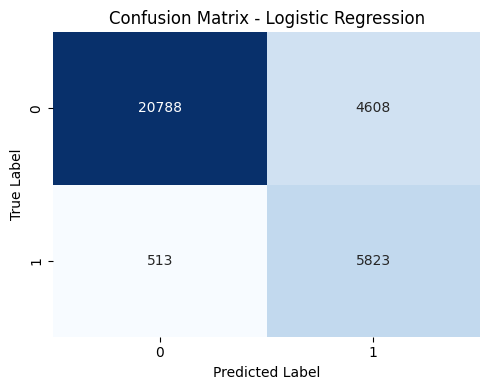


--- Đang huấn luyện: Decision Tree ---
Accuracy: 0.8157 | F1 lớp 1: 0.5096

Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.90      0.89     25396
           1       0.54      0.48      0.51      6336

    accuracy                           0.82     31732
   macro avg       0.71      0.69      0.70     31732
weighted avg       0.81      0.82      0.81     31732



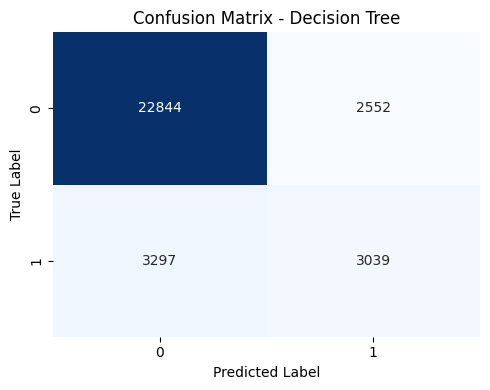


Model tốt nhất: Logistic Regression (F1 lớp 1 = 0.6946)


In [8]:
best_model = None
best_f1 = 0
best_model_name = ""

for name, model in models.items():
    print(f"\n--- Đang huấn luyện: {name} ---")
    model.fit(X_train, y_train)  #
    y_pred = model.predict(X_test)
    
    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    print(f"Accuracy: {acc:.4f} | F1 lớp 1: {f1:.4f}")
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred))
    
   
    plt.figure(figsize=(5, 4))
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
    plt.title(f'Confusion Matrix - {name}')
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')
    plt.tight_layout()
    plt.show()
    
    if f1 > best_f1:
        best_f1 = f1
        best_model = model
        best_model_name = name
    
print(f"\nModel tốt nhất: {best_model_name} (F1 lớp 1 = {best_f1:.4f})")

**Nhận xét:** Nhãn `High_Value` = 1 khi Sales Amount lớn hơn phân vị 75 (khoảng 6,0); lớp 1 chiếm 20% nên dùng `class_weight='balanced'`

- Logistic Regression: accuracy 0,8386, F1 lớp 1 = 0,6946 (recall 0,92, precision 0,56)
- Decision Tree (max_depth=8): accuracy 0,8157, F1 lớp 1 = 0,5096 (recall 0,48, precision 0,54)

-> **Logistic Regression thắng**, chủ yếu vì bắt được nhiều giao dịch giá trị cao hơn (recall 0,92 so với 0,48)

`Quantity` và `Price` bị loại khỏi feature vì Sales Amount = Quantity x Price, giữ lại sẽ gây rò rỉ nhãn

# 8. Xuất mô hình tốt nhất ra file .pkl

In [9]:
model_filename = '../Stage2/models/PhamVietTien_classfication_model.pkl'
with open(model_filename, 'wb') as file:
    pickle.dump(best_model, file)